# Chapitre 3 - Lab : les index de PostgreSQL vus de l'intérieur

Ce lab confronte le cours à un vrai moteur : PostgreSQL 16, qui range ses tables dans un
**fichier de tas** et ses index dans des **B-trees** (cours 3 et 4). Nous allons :

1. mesurer un parcours séquentiel et lire un plan d'exécution (`EXPLAIN ANALYZE`) ;
2. inspecter la structure réelle d'un index B-tree (extension `pageinspect`) et observer
   le choix du plan selon la sélectivité ;
3. obtenir un **index-only scan** grâce à un index couvrant (`INCLUDE`) ;
4. mesurer le coût des index en écriture, en octets de **WAL** ;
5. observer la **fragmentation** après des suppressions et le rôle de `VACUUM` ;
6. construire un index **GIN** pour la recherche plein texte.

**Démarrer et arrêter les services** (depuis la racine du dépôt) :

```bash
docker compose -f docker/storage/compose.yml -p ddia_storage up -d     # démarrer
docker compose -f docker/storage/compose.yml -p ddia_storage down -v   # arrêter et effacer
```

PostgreSQL écoute sur le port **10432** de la machine (utilisateur, mot de passe et base :
`ddia` / `ddia` / `stockage`).

In [1]:
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import psycopg

from ddia import storage as S
from ddia.diagrams import Diagram
from ddia.plotting import (AMBER, COLORS, GRAY, GREEN, INDIGO, LIGHT, ROSE, SKY, SLATE, TEAL, VIOLET,
                           annotate_bars, finish, set_style, subtitle)

set_style()
plt.rcParams["axes.titlepad"] = 16
pd.set_option("display.precision", 3)
pd.set_option("display.max_colwidth", 120)

DSN = "host=localhost port=10432 user=ddia password=ddia dbname=stockage"
con = None
for essai in range(30):
    try:
        con = psycopg.connect(DSN, autocommit=True)
        break
    except psycopg.OperationalError:
        time.sleep(1)
assert con is not None, "PostgreSQL ne répond pas : avez-vous lancé docker compose up ?"
print(con.execute("SELECT version()").fetchone()[0][:60])


def q(sql, params=None):
    """Exécute une requête et renvoie toutes les lignes."""
    return con.execute(sql, params).fetchall()


def plan(sql):
    """Plan réel (EXPLAIN ANALYZE, BUFFERS) sous forme de texte."""
    return "\n".join(r[0] for r in q("EXPLAIN (ANALYZE, BUFFERS, TIMING OFF, SUMMARY OFF) " + sql))


def plan_json(sql):
    return q("EXPLAIN (ANALYZE, BUFFERS, FORMAT JSON) " + sql)[0][0][0]

PostgreSQL 16.14 (Debian 16.14-1.pgdg13+1) on x86_64-pc-linu


## 1. Une table et un parcours séquentiel (section *Data Structures That Power Your Database*)

On crée une table de commandes d'un million de lignes, générée côté serveur
(`generate_series`) avec une graine fixe. PostgreSQL range les lignes dans un **tas** :
des pages de 8 Kio, dans l'ordre d'insertion, sans index pour l'instant.

In [2]:
con.execute("DROP TABLE IF EXISTS commandes")
con.execute("""
CREATE TABLE commandes (
    id        bigint,
    client    int,
    statut    text,
    jour      int,
    montant   numeric(10, 2),
    adresse   text
)""")
con.execute("SELECT setseed(0.42)")
con.execute("""
INSERT INTO commandes
SELECT g,
       (100000 * random() ^ 2)::int,                       -- clients : quelques gros clients
       (ARRAY['livrée','livrée','livrée','expédiée','payée','annulée'])[1 + (random() * 5)::int],
       (random() * 364)::int,
       round((random() * 200)::numeric, 2),
       repeat('x', 80)
FROM generate_series(1, 1000000) AS g""")
con.execute("VACUUM ANALYZE commandes")
taille = q("SELECT pg_relation_size('commandes'), pg_size_pretty(pg_relation_size('commandes'))")[0]
print(f"table : {taille[1]}, soit {taille[0] // 8192} pages de 8 Kio")
print(plan("SELECT sum(montant) FROM commandes WHERE client = 4242"))

table : 137 MB, soit 17555 pages de 8 Kio
Finalize Aggregate  (cost=23763.58..23763.59 rows=1 width=32) (actual rows=1 loops=1)
  Buffers: shared hit=17555
  ->  Gather  (cost=23763.35..23763.56 rows=2 width=32) (actual rows=3 loops=1)
        Workers Planned: 2
        Workers Launched: 2
        Buffers: shared hit=17555
        ->  Partial Aggregate  (cost=22763.35..22763.36 rows=1 width=32) (actual rows=1 loops=3)
              Buffers: shared hit=17555
              ->  Parallel Seq Scan on commandes  (cost=0.00..22763.33 rows=7 width=6) (actual rows=10 loops=3)
                    Filter: (client = 4242)
                    Rows Removed by Filter: 333323
                    Buffers: shared hit=17555
Planning:
  Buffers: shared hit=29 read=2


Le plan montre un `Seq Scan` (parcours séquentiel, ici en parallèle) : PostgreSQL lit
**toutes** les pages du tas (`Buffers: shared hit=... read=...` : pages trouvées dans
son cache ou lues) pour trouver une poignée de lignes. C'est notre `db_get` du cours 1,
en plus rapide.

> **À retenir.** Sans index, toute requête sélective coûte un parcours de la table
> entière : le nombre de pages lues est la taille de la table.

## 2. Un index B-tree, vu de l'intérieur (section *B-Trees*)

Créons deux index B-tree, sur `id` (valeurs uniques) et sur `client` (beaucoup de
doublons), et inspectons-les avec l'extension `pageinspect` : `bt_metap` donne le niveau
de la racine (la hauteur moins un), `bt_multi_page_stats` le contenu de chaque page
(type `r` racine, `i` interne, `l` feuille).

In [3]:
con.execute("CREATE EXTENSION IF NOT EXISTS pageinspect")
con.execute("CREATE INDEX idx_id ON commandes(id)")
con.execute("CREATE INDEX idx_client ON commandes(client)")
lignes = []
for idx in ["idx_id", "idx_client"]:
    niveau = q(f"SELECT level FROM bt_metap('{idx}')")[0][0]
    for typ, n, items, taille_item, libre in q(f"""
            SELECT type, count(*), avg(live_items), avg(avg_item_size), avg(free_size)
            FROM bt_multi_page_stats('{idx}', 1, -1) GROUP BY type ORDER BY type DESC"""):
        lignes.append(dict(index=idx, hauteur=niveau + 1, type={"r": "racine", "i": "interne", "l": "feuille"}[typ],
                           pages=n, entrees_par_page=float(items), octets_par_entree=float(taille_item),
                           octets_libres=float(libre)))
pd.DataFrame(lignes).round(0)

,index,hauteur,type,pages,entrees_par_page,octets_par_entree,octets_libres
0,idx_id,3,racine,1,10.0,15.0,7956.0
1,idx_id,3,feuille,2733,367.0,16.0,810.0
2,idx_id,3,interne,10,274.0,15.0,2672.0
3,idx_client,3,racine,1,4.0,14.0,8076.0
4,idx_client,3,feuille,1128,90.0,119.0,775.0
5,idx_client,3,interne,4,283.0,15.0,2453.0


Un million d'entrées tiennent dans un arbre de **3 niveaux** : une racine, quelques
pages internes de plusieurs centaines d'entrées, et des feuilles. Pour `idx_id`, chaque
feuille contient environ 370 entrées de 16 octets (clé de 8 octets, identifiant de ligne
de 6 octets, alignement) et les pages sont presque pleines (l'index a été construit
d'un coup, en triant). Pour `idx_client`, les feuilles sont bien moins nombreuses
qu'attendu : depuis la version 13, PostgreSQL **déduplique** les entrées d'une même clé
en une seule entrée suivie de la **liste des identifiants de lignes**. C'est exactement
la première méthode d'index secondaire du cours 4 (une liste par valeur, comme une
postings list), d'où des entrées plus grosses mais beaucoup moins nombreuses.

**Hauteur selon la taille.** Construisons des index sur des tables de tailles
croissantes : la hauteur grandit d'un niveau à chaque facteur de quelques centaines.

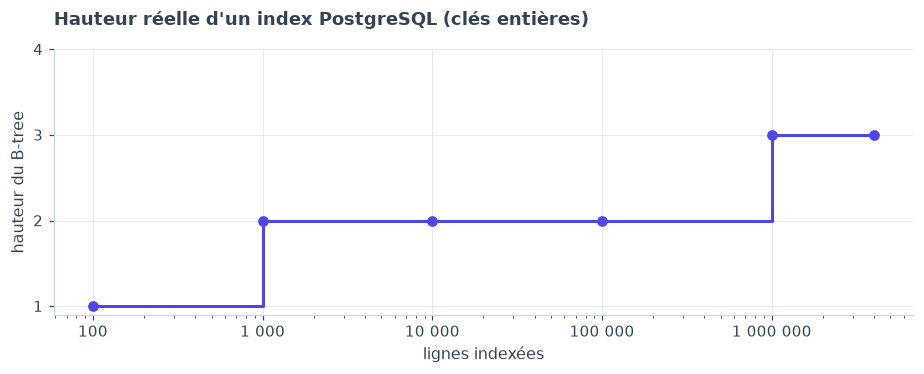

,lignes,hauteur,pages_index
0,100,1,2
1,1000,2,5
2,10000,2,30
3,100000,2,276
4,1000000,3,2745
5,4000000,3,10970


In [4]:
rows = []
for n in [100, 1_000, 10_000, 100_000, 1_000_000, 4_000_000]:
    con.execute("DROP TABLE IF EXISTS t_h")
    con.execute(f"CREATE TABLE t_h AS SELECT g AS k FROM generate_series(1, {n}) g")
    con.execute("CREATE INDEX t_h_k ON t_h(k)")
    lv = q("SELECT level FROM bt_metap('t_h_k')")[0][0]
    pages = q("SELECT pg_relation_size('t_h_k') / 8192")[0][0]
    rows.append(dict(lignes=n, hauteur=lv + 1, pages_index=pages))
con.execute("DROP TABLE t_h")
haut = pd.DataFrame(rows)
fig, ax = plt.subplots(figsize=(8.5, 3.5))
ax.step(haut.lignes, haut.hauteur, where="post", color=INDIGO, lw=2)
ax.plot(haut.lignes, haut.hauteur, "o", color=INDIGO)
ax.set_xscale("log"); S.plain_log_ticks(ax, "x")
ax.set_yticks(range(1, 5)); ax.set_xlabel("lignes indexées"); ax.set_ylabel("hauteur du B-tree")
ax.set_title("Hauteur réelle d'un index PostgreSQL (clés entières)")
plt.tight_layout(); plt.show()
haut

**Le choix du plan selon la sélectivité.** Le cours 4 prévoyait qu'un index secondaire
sur un tas ne bat un parcours séquentiel que pour des requêtes **sélectives**. Faisons
varier la fraction de lignes sélectionnées (par un intervalle de clients) et notons le
plan choisi par l'optimiseur et le nombre de pages touchées.

In [5]:
con.execute("CREATE INDEX idx_jour ON commandes(jour)")
con.execute("ANALYZE commandes")
rows = []
for jours in [1, 3, 10, 30, 90, 180, 365]:
    sql = f"SELECT sum(montant) FROM commandes WHERE jour < {jours}"
    pj = plan_json(sql)

    def noeuds(nd):
        yield nd
        for c in nd.get("Plans", []):
            yield from noeuds(c)

    types = [nd["Node Type"] for nd in noeuds(pj["Plan"])]
    principal = next(t for t in types if "Scan" in t)
    t0 = time.perf_counter()
    q(sql)
    rows.append(dict(fraction=jours / 365, plan=principal, pages=pj["Plan"].get("Shared Hit Blocks", 0)
                     + pj["Plan"].get("Shared Read Blocks", 0), ms=(time.perf_counter() - t0) * 1e3))
sel = pd.DataFrame(rows)
sel

,fraction,plan,pages,ms
0,0.003,Bitmap Heap Scan,1319,0.636
1,0.008,Bitmap Heap Scan,5765,2.249
2,0.027,Bitmap Heap Scan,13710,6.467
3,0.082,Bitmap Heap Scan,17498,15.324
4,0.247,Bitmap Heap Scan,17770,29.863
5,0.493,Seq Scan,17555,23.727
6,1.000,Seq Scan,17555,26.491


Pour les requêtes sélectives, l'optimiseur choisit l'index, sous la forme d'un `Bitmap
Index Scan` suivi d'un `Bitmap Heap Scan` : il construit d'abord un bitmap des pages du
tas à visiter, puis les lit **dans l'ordre physique**, chacune une seule fois. Cette
astuce transforme des lectures aléatoires en lectures presque séquentielles, et repousse
loin le point de bascule : ici, le `Seq Scan` ne revient que vers la moitié des lignes.
Mais la colonne `pages` montre la limite prévue par le cours 4 : avec environ 57 lignes
par page, dès quelques pourcents de lignes sélectionnées, presque **toutes** les pages
du tas contiennent au moins une ligne voulue
($1 - (1 - s)^{57}$ vaut déjà 80 % pour $s = 3\,\%$), et l'index ne fait plus gagner
de pages. (Le seuil exact dépend des statistiques et des paramètres `random_page_cost`
et `seq_page_cost`.)

> **À retenir.** Un vrai B-tree PostgreSQL a 3 ou 4 niveaux pour des millions de
> lignes. L'optimiseur n'utilise un index secondaire que si la requête est assez
> sélective : sinon, le parcours séquentiel du tas est moins cher.

## 3. Index couvrant et index-only scan (section *Storing values within the index*)

Avec `idx_client`, la requête « montant total d'un client » doit aller chercher chaque
ligne dans le tas. Un index **couvrant** stocke aussi `montant` (clause `INCLUDE`) : la
requête peut se contenter de l'index (`Index Only Scan`). Subtilité de PostgreSQL : à
cause du contrôle de concurrence multiversion (chapitre 7), il doit
vérifier dans la **carte de visibilité** que les pages du tas ne contiennent que des
lignes visibles par tous ; tant que `VACUUM` ne l'a pas mise à jour, il retourne au tas
(`Heap Fetches`).

In [6]:
requete = "SELECT sum(montant) FROM commandes WHERE client BETWEEN 1 AND 30"
lignes = []
pj = plan_json(requete)
lignes.append(dict(etape="index simple (client)", plan=pj["Plan"]["Plans"][0]["Node Type"]
                   if "Plans" in pj["Plan"] else pj["Plan"]["Node Type"],
                   pages=pj["Plan"]["Shared Hit Blocks"] + pj["Plan"]["Shared Read Blocks"], heap_fetches=None))
con.execute("CREATE INDEX idx_client_couvrant ON commandes(client) INCLUDE (montant)")
con.execute("UPDATE commandes SET montant = montant + 0 WHERE id % 50 = 0")  # des pages deviennent « sales »
con.execute("ANALYZE commandes")


def detail(pj):
    n = pj["Plan"]
    while "Plans" in n and n["Node Type"] in ("Aggregate", "Gather", "Finalize Aggregate", "Partial Aggregate"):
        n = n["Plans"][0]
    return n


pj = plan_json(requete)
d = detail(pj)
lignes.append(dict(etape="index couvrant, avant VACUUM", plan=d["Node Type"],
                   pages=pj["Plan"]["Shared Hit Blocks"] + pj["Plan"]["Shared Read Blocks"],
                   heap_fetches=d.get("Heap Fetches")))
con.execute("VACUUM commandes")
pj = plan_json(requete)
d = detail(pj)
lignes.append(dict(etape="index couvrant, après VACUUM", plan=d["Node Type"],
                   pages=pj["Plan"]["Shared Hit Blocks"] + pj["Plan"]["Shared Read Blocks"],
                   heap_fetches=d.get("Heap Fetches")))
cov = pd.DataFrame(lignes)
cov

,etape,plan,pages,heap_fetches
0,index simple (client),Bitmap Heap Scan,10267,NaN
1,"index couvrant, avant VACUUM",Bitmap Heap Scan,10469,NaN
2,"index couvrant, après VACUUM",Index Only Scan,64,0.0


Avant `VACUUM`, l'`UPDATE` (une ligne sur 50, donc presque toutes les pages) a effacé
la carte de visibilité : un index-only scan devrait de toute façon retourner au tas pour
presque chaque ligne, et l'optimiseur préfère un `Bitmap Heap Scan`, qui touche plus de
10 000 pages. Après `VACUUM`, le plan devient un `Index Only Scan` sans aucune visite du
tas (`Heap Fetches` = 0) : quelques dizaines de pages seulement, celles de l'index.

> **À retenir.** `INCLUDE` rend un index couvrant ; PostgreSQL obtient alors un index-only
> scan, à condition que la carte de visibilité soit à jour (rôle de `VACUUM`).

## 4. Le coût des index en écriture, en octets de WAL (section *Comparing B-Trees and LSM-Trees*)

Chaque modification d'une page est d'abord décrite dans le **WAL** (cours 3). La
fonction `pg_current_wal_lsn()` donne la position courante dans le journal : la
différence avant/après une opération mesure les octets de WAL qu'elle a produits.
Insérons 20 000 lignes dans des tables munies de 0 à 4 index.

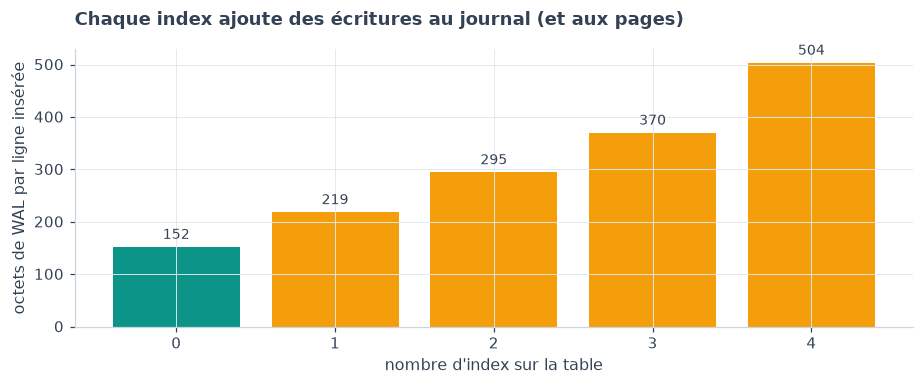

,index,wal_Mo,wal_octets_par_ligne
0,0,3.049,152.450
1,1,4.374,218.703
2,2,5.897,294.852
3,3,7.406,370.278
4,4,10.073,503.661


In [7]:
def wal_pos():
    return q("SELECT pg_current_wal_lsn()")[0][0]


def wal_octets(a, b):
    return q("SELECT pg_wal_lsn_diff(%s, %s)", (b, a))[0][0]


rows = []
utile = None
for n_idx in range(5):
    con.execute("DROP TABLE IF EXISTS t_w")
    con.execute("CREATE TABLE t_w (id bigint, a int, b int, c text, d int, pad text)")
    for j, col in enumerate(["id", "a", "b", "c"][:n_idx]):
        con.execute(f"CREATE INDEX t_w_{col} ON t_w({col})")
    con.execute("CHECKPOINT")
    a = wal_pos()
    con.execute("""INSERT INTO t_w SELECT g, (random() * 1e6)::int, (random() * 1e6)::int, md5(g::text),
                   g % 100, repeat('y', 40) FROM generate_series(1, 20000) g""")
    b = wal_pos()
    if utile is None:
        utile = q("SELECT pg_relation_size('t_w')")[0][0]
    rows.append(dict(index=n_idx, wal_Mo=float(wal_octets(a, b)) / 1e6,
                     wal_octets_par_ligne=float(wal_octets(a, b)) / 20_000))
con.execute("DROP TABLE t_w")
wal = pd.DataFrame(rows)
fig, ax = plt.subplots(figsize=(8.5, 3.6))
ax.bar(wal["index"], wal.wal_octets_par_ligne, color=[TEAL] + [AMBER] * 4)
annotate_bars(ax, "{:.0f}")
ax.set_xlabel("nombre d'index sur la table"); ax.set_ylabel("octets de WAL par ligne insérée")
ax.set_title("Chaque index ajoute des écritures au journal (et aux pages)")
plt.tight_layout(); plt.show()
wal

Le volume de WAL par ligne croît avec chaque index : il faut journaliser l'insertion dans
le tas **et** dans chaque B-tree (avec, de temps en temps, un éclatement de page). Les
premières modifications d'une page après un point de reprise (`CHECKPOINT`) écrivent
même la **page entière** dans le WAL (*full page writes*), pour se protéger des pages
déchirées : c'est l'écriture de pages entières dont parle le livre. Mesurons cet effet en
modifiant une ligne par page juste après un point de reprise, puis une seconde fois.

In [8]:
con.execute("CHECKPOINT")
a = wal_pos()
con.execute("UPDATE commandes SET jour = jour WHERE id % 60 = 1")
b = wal_pos()
con.execute("UPDATE commandes SET jour = jour WHERE id % 60 = 2")
c = wal_pos()
n_maj = q("SELECT count(*) FROM commandes WHERE id % 60 = 1")[0][0]
fpw = pd.Series({"1re mise à jour après CHECKPOINT (octets de WAL par ligne)": float(wal_octets(a, b)) / n_maj,
                 "2e mise à jour, mêmes pages (octets de WAL par ligne)": float(wal_octets(b, c)) / n_maj})
fpw.round(0).to_frame("valeur")

,valeur
1re mise à jour après CHECKPOINT (octets de WAL par ligne),8467.0
"2e mise à jour, mêmes pages (octets de WAL par ligne)",448.0


La première vague de mises à jour coûte plusieurs Kio de WAL par ligne (des images de
pages complètes de 8 Kio, pour le tas et pour les index touchés), la seconde quelques
centaines d'octets seulement : la page a déjà été journalisée en entier depuis le point
de reprise. Une amplification d'écriture bien réelle, propre aux structures qui
modifient des pages en place.

> **À retenir.** Chaque index ajoute des écritures (WAL et pages). Les *full page
> writes* après un point de reprise rendent la première modification d'une page très
> coûteuse : c'est le prix de la protection contre les pages déchirées.

## 5. Fragmentation et VACUUM (section *Comparing B-Trees and LSM-Trees*)

Supprimons 70 % des commandes et observons la taille de la table et de l'index : les
pages libérées restent dans le fichier.

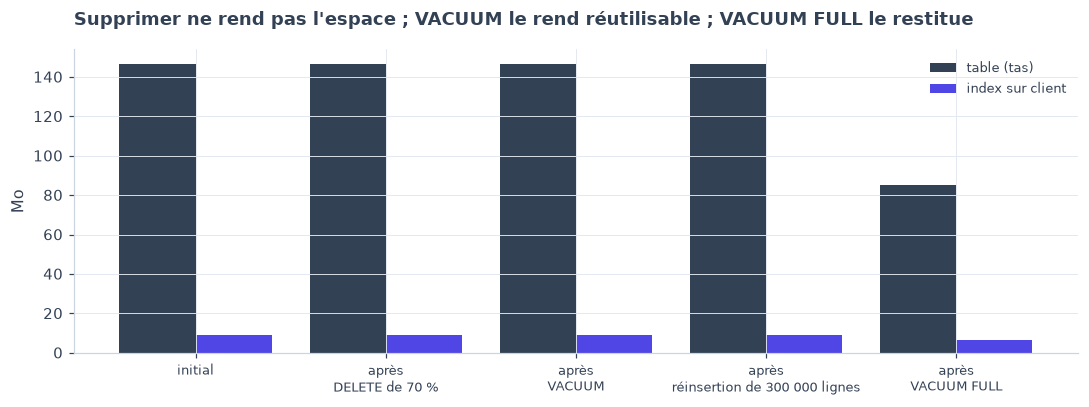

,etape,table_Mo,index_client_Mo,lignes
0,initial,146.678,9.290,1000000
1,après DELETE de 70 %,146.678,9.290,300000
2,après VACUUM,146.678,9.290,300000
3,après réinsertion de 300 000 lignes,146.678,9.290,600000
4,après VACUUM FULL,85.443,6.537,600000


In [9]:
def tailles(etape):
    t, i = q("SELECT pg_relation_size('commandes'), pg_relation_size('idx_client')")[0]
    return dict(etape=etape, table_Mo=t / 1e6, index_client_Mo=i / 1e6,
                lignes=q("SELECT count(*) FROM commandes")[0][0])


etapes = [tailles("initial")]
con.execute("DELETE FROM commandes WHERE id % 10 < 7")
etapes.append(tailles("après DELETE de 70 %"))
con.execute("VACUUM commandes")
etapes.append(tailles("après VACUUM"))
con.execute("""INSERT INTO commandes SELECT g, (100000 * random() ^ 2)::int, 'payée', 0, 1, repeat('x', 80)
               FROM generate_series(2000001, 2300000) g""")
etapes.append(tailles("après réinsertion de 300 000 lignes"))
con.execute("VACUUM FULL commandes")
etapes.append(tailles("après VACUUM FULL"))
frag = pd.DataFrame(etapes)
fig, ax = plt.subplots(figsize=(10, 3.8))
x = np.arange(len(frag))
ax.bar(x - 0.2, frag.table_Mo, 0.4, color=SLATE, label="table (tas)")
ax.bar(x + 0.2, frag.index_client_Mo, 0.4, color=INDIGO, label="index sur client")
ax.set_xticks(x, [e.replace("après ", "après\n") for e in frag.etape], fontsize=8.5)
ax.set_ylabel("Mo"); ax.set_title("Supprimer ne rend pas l'espace ; VACUUM le rend réutilisable ; VACUUM FULL le restitue")
ax.legend(fontsize=8.5)
plt.tight_layout(); plt.show()
frag

Le `DELETE` ne change pas la taille du fichier (les lignes sont seulement marquées
mortes, à cause du contrôle de concurrence multiversion). `VACUUM` libère l'espace pour
de futures insertions sans rendre le fichier plus petit : les 300 000 nouvelles lignes
se logent dans les trous, sans faire grossir la table. Seul `VACUUM FULL`, qui réécrit
la table et ses index (comme une compaction, en bloquant la table), restitue l'espace au
système.

> **À retenir.** Un moteur à mise à jour en place se fragmente : l'espace libéré reste
> dans le fichier. `VACUUM` le rend réutilisable, `VACUUM FULL` (une réécriture
> complète) le restitue.

## 6. Un index GIN pour la recherche plein texte (section *Full-text search and fuzzy indexes*)

L'index **GIN** (*Generalized Inverted Index*) de PostgreSQL est un **index inversé** :
pour chaque terme, une liste triée des lignes qui le contiennent (cours 4). Chargeons
50 000 documents synthétiques et comparons la recherche par parcours et par index.

In [10]:
vocab = S.make_vocabulary(5_000, seed=0)
docs = S.make_documents(50_000, vocab, words_per_doc=40, s=1.05, seed=1)
con.execute("DROP TABLE IF EXISTS docs")
con.execute("CREATE TABLE docs (id int PRIMARY KEY, corps text)")
with con.cursor() as cur:
    with cur.copy("COPY docs (id, corps) FROM STDIN") as cp:
        for i, d_ in enumerate(docs):
            cp.write_row((i, d_))
con.execute("ALTER TABLE docs ADD COLUMN tsv tsvector GENERATED ALWAYS AS (to_tsvector('simple', corps)) STORED")
con.execute("ANALYZE docs")
rare1, rare2 = vocab[300], vocab[400]
requete_ft = f"SELECT count(*) FROM docs WHERE tsv @@ to_tsquery('simple', '{rare1} & {rare2}')"
t0 = time.perf_counter(); n_res = q(requete_ft)[0][0]; t_scan = time.perf_counter() - t0
plan_sans = plan(requete_ft)
t0 = time.perf_counter()
con.execute("CREATE INDEX docs_gin ON docs USING gin(tsv)")
t_build = time.perf_counter() - t0
con.execute("ANALYZE docs")
t0 = time.perf_counter(); n_res2 = q(requete_ft)[0][0]; t_gin = time.perf_counter() - t0
assert n_res == n_res2
print(f"« {rare1} & {rare2} » : {n_res} documents ; parcours {t_scan * 1e3:.1f} ms, "
      f"GIN {t_gin * 1e3:.2f} ms (index construit en {t_build:.1f} s, "
      f"{q('SELECT pg_size_pretty(pg_relation_size(%s))', ('docs_gin',))[0][0]})")
print(plan(requete_ft))

« enttionnoro & sina » : 4 documents ; parcours 12.6 ms, GIN 0.50 ms (index construit en 0.3 s, 5560 kB)
Aggregate  (cost=45.03..45.04 rows=1 width=8) (actual rows=1 loops=1)
  Buffers: shared hit=11
  ->  Bitmap Heap Scan on docs  (cost=21.54..45.02 rows=6 width=0) (actual rows=4 loops=1)
        Recheck Cond: (tsv @@ '''enttionnoro'' & ''sina'''::tsquery)
        Heap Blocks: exact=4
        Buffers: shared hit=11
        ->  Bitmap Index Scan on docs_gin  (cost=0.00..21.54 rows=6 width=0) (actual rows=4 loops=1)
              Index Cond: (tsv @@ '''enttionnoro'' & ''sina'''::tsquery)
              Buffers: shared hit=7
Planning:
  Buffers: shared hit=1


Sans index, PostgreSQL parcourt les 50 000 vecteurs de termes ; avec GIN, il consulte les
postings lists des deux termes, les **intersecte** (`Bitmap Index Scan` avec la
condition sur les deux termes) puis ne visite que les lignes trouvées. L'index GIN sert
aussi à indexer l'intérieur des documents JSON (opérateurs `@>` sur `jsonb`).

> **À retenir.** GIN est l'index inversé de PostgreSQL : postings lists par terme,
> intersection pour les requêtes à plusieurs termes, et seulement les lignes trouvées à
> lire.

## Synthèse et nettoyage

- Un parcours séquentiel lit toute la table ; un index B-tree de 3 niveaux trouve une
  ligne en quelques pages (et déduplique les clés répétées en listes d'identifiants) ;
  l'optimiseur ne l'utilise que pour des requêtes assez sélectives.
- `INCLUDE` donne des index couvrants et des index-only scans (avec une carte de
  visibilité à jour).
- Chaque index se paie en WAL et en pages ; les *full page writes* rendent visible
  l'amplification d'écriture d'un moteur à mise à jour en place.
- Le tas se fragmente ; `VACUUM` rend l'espace réutilisable, `VACUUM FULL` le restitue.
- GIN est un index inversé pour le plein texte.

Pour arrêter et effacer les conteneurs du lab :

```bash
docker compose -f docker/storage/compose.yml -p ddia_storage down -v
```

In [11]:
con.close()